In [2]:
import pandas as pd
import networkx as nx   # to create the network graph
import matplotlib.pyplot as plt
import re

In [3]:
def parse_link(link):
    # convert link into source and destination nodes
    link = str(link).strip()
    
    parts = re.split(r"\s*-\s*", link)
    if len(parts) == 2:
        return parts[0].strip(), parts[1].strip()

    return None, None

In [4]:
def df_to_nx_graph(url):
    print("\nLoading the Zenodo dataset...")
    df = pd.read_csv(url)
    print("Columns:", df.columns.tolist())

    print("\nExtracting unique links from the dataset...")
    unique_links = df["link"].unique()
    graph_df = pd.DataFrame({"link": unique_links})
    print("Unique links:")
    print(graph_df)

    print("\nExtracting source and destination nodes...")
    graph_df[["Source", "Destination"]] = graph_df["link"].apply(
        lambda x: pd.Series(parse_link(x))
    )
    print("Extracted nodes:")
    print(graph_df[["link", "Source", "Destination"]])

    print("\nCreating a directed graph...")
    G = nx.Graph()

    print("\nAdding edges to the graph...")
    G.add_edges_from(
        graph_df[["Source", "Destination"]].itertuples(
            index=False,
            name=None
        )
    )

    print("Nodes:", list(G.nodes()))
    print("Edges:", list(G.edges()))

    print("\nDrawing the graph...")
    plt.figure(figsize=(10, 8))
    pos = nx.spring_layout(G)
    nx.draw(G, pos, with_labels=True, node_size=2000, node_color='lightblue', font_size=10, font_weight='bold', arrows=True)
    plt.title("Network Graph from Zenodo Dataset")
    plt.show()


Loading the Zenodo dataset...
Columns: ['timestamp', 'link', 'packet_loss', 'jitter', 'outflow_Router', 'inflow_Router', 'resolve', 'avalability', 'ttl', 'probe_duration', 'rtt', 'LABEL']

Extracting unique links from the dataset...
Unique links:
     link
0   R1-R9
1   R8-R6
2   R4-R5
3   R8-R7
4   R7-R6
5   R3-R8
6   R1-R2
7   R9-R8
8   R2-R9
9   R2-R3
10  R6-R5
11  R4-R6
12  R3-R4

Extracting source and destination nodes...
Extracted nodes:
     link Source Destination
0   R1-R9     R1          R9
1   R8-R6     R8          R6
2   R4-R5     R4          R5
3   R8-R7     R8          R7
4   R7-R6     R7          R6
5   R3-R8     R3          R8
6   R1-R2     R1          R2
7   R9-R8     R9          R8
8   R2-R9     R2          R9
9   R2-R3     R2          R3
10  R6-R5     R6          R5
11  R4-R6     R4          R6
12  R3-R4     R3          R4

Creating a directed graph...

Adding edges to the graph...
Nodes: ['R1', 'R9', 'R8', 'R6', 'R4', 'R5', 'R7', 'R3', 'R2']
Edges: [('R1', 'R9'), (

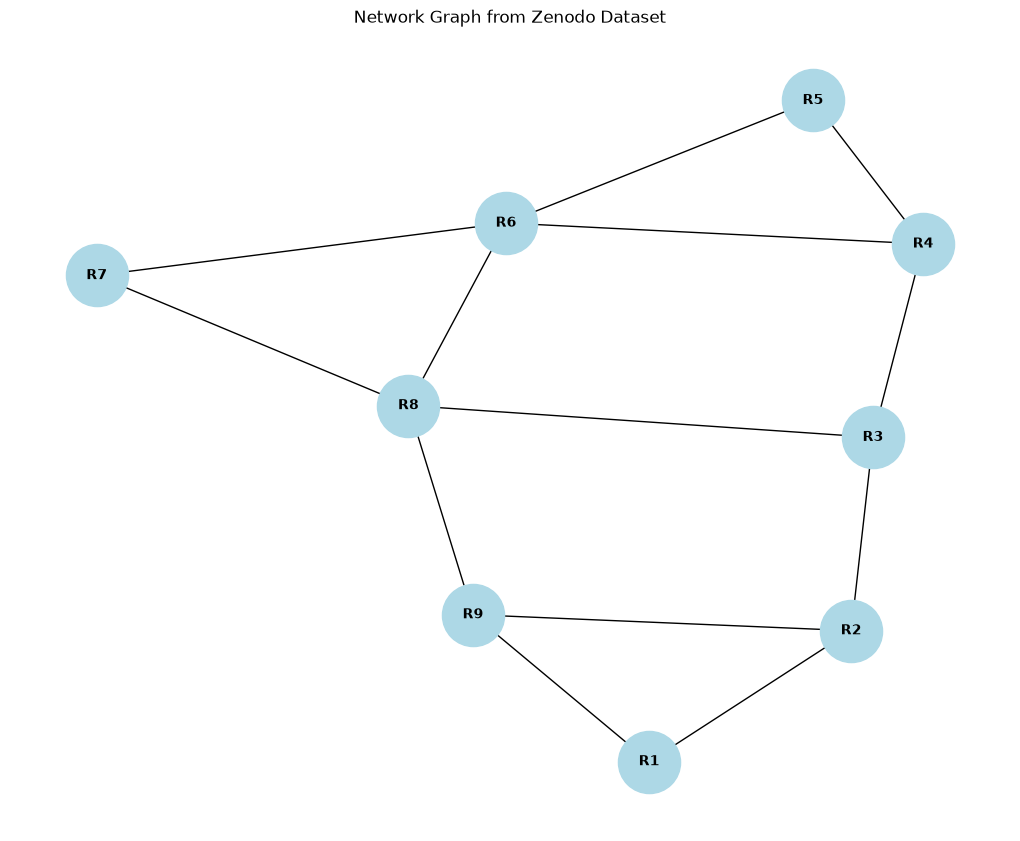

In [5]:
df_to_nx_graph("dataset/dataset_01_TC33_27062025_labeled.csv")

In [8]:
df = pd.read_csv("dataset/dataset_01_TC33_27062025_labeled.csv")
df.head(20)

,timestamp,link,packet_loss,jitter,outflow_Router,inflow_Router,resolve,avalability,ttl,probe_duration,rtt,LABEL
0,1750858080,R1-R9,0.00,0.17,4.65,4.60,0.01,1.0,62.0,0.00,0.98,0.0
1,1750858080,R8-R6,0.00,0.17,4.64,4.64,0.01,1.0,62.0,0.00,1.70,0.0
2,1750858080,R4-R5,0.00,0.32,69.69,69.59,0.05,1.0,62.0,0.00,1.66,0.0
3,1750858080,R8-R7,0.00,0.03,4.65,4.65,0.01,1.0,62.0,0.00,0.91,0.0
4,1750858080,R7-R6,0.00,0.08,4.64,4.65,0.01,1.0,62.0,0.00,0.95,0.0
5,1750858080,R3-R8,0.00,0.24,4.65,4.64,0.53,1.0,61.0,0.01,2.59,0.0
6,1750858080,R1-R2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
7,1750858080,R9-R8,0.00,0.25,4.64,4.65,0.04,1.0,62.0,0.00,1.01,0.0
8,1750858080,R2-R9,0.00,0.20,4.66,4.60,0.03,1.0,62.0,0.00,0.96,0.0
9,1750858080,R2-R3,0.00,0.14,69.75,69.64,0.05,1.0,62.0,0.00,1.84,0.0
